# Phase 1 · Lesson 4: Visualisation for EDA
**ML Engineer Journey · Benson M. Merita**

**Goal:** use charts as an **ML diagnostic tool**, not decoration. Before training any model you need to know each feature's distribution, how features relate to each other and to the target, and where the data could fool you. Here you'll:
- master Matplotlib's **object model** (`fig, ax`), so every chart is controllable and reusable;
- build a **kernel density estimate (KDE)** from scratch and meet your first **bias–variance trade-off**;
- compute a **correlation matrix** from scratch (it's Lesson 2's covariance, standardised);
- catch **Simpson's paradox** in real data, a mistake a plain correlation table would hide.

| Section | What you get |
|---|---|
| 1 · Intuition | What EDA must answer before modelling |
| 2 · The math | KDE, bandwidth, Freedman–Diaconis bins, correlation as $Z^\top Z/(n-1)$ |
| 3 · From scratch | Matplotlib object model, NumPy KDE, NumPy correlation matrix |
| 4 · With libraries | Seaborn: `histplot`, `kdeplot`, `boxplot`, `scatterplot`, `heatmap`, `pairplot`; `scipy.stats.gaussian_kde` |
| 5 · Dataset | Palmer Penguins (via seaborn) |
| 6–8 | Exercises, quiz, mistakes & interview questions |
| 🎬 Demo | Bandwidth GIF, Simpson's paradox chart, interactive slider |

---
## 1 · Intuition

Imagine being handed 344 penguin records and told "build a model". A good engineer **looks** first, asking five questions:

1. **What does each feature look like?** Is it symmetric, skewed, or two-humped? A two-humped (bimodal) distribution usually means two hidden groups are mixed together.
2. **Is the target balanced?** If 95% of cases are one class, accuracy will lie to you (Phase 5).
3. **How do features relate to the target?** That tells you which features are likely to be useful.
4. **How do features relate to each other?** Strongly correlated pairs mean redundancy and unstable linear weights (Lesson 2's condition number).
5. **What could mislead me?** Outliers, missing values, and *groups* that reverse a trend.

Charts answer these in seconds. Summary statistics can't: datasets with identical means, variances and correlations can look completely different (Anscombe's quartet, or the "Datasaurus").

**Real ML engineering connection:** EDA plots return in production as **data-drift monitoring**, comparing today's feature distributions with the training data (Phase 7), and as **model diagnostics** such as residual plots, ROC curves and learning curves (Phases 3–5). The `fig, ax` habits you learn here are what make those plots scriptable.

---
## 2 · The math

**Histogram as a density estimate.** With bin width $h$, $\hat f(x) = \dfrac{\#\{x_i \text{ in } x\text{'s bin}\}}{n h}$. The result depends heavily on $h$ and on where the bins start.
**Freedman–Diaconis rule:** $h = 2\,\mathrm{IQR}\; n^{-1/3}$, which is robust to outliers.

**Kernel density estimate.** Replace the hard bins with a smooth "bump" $K$ (here a Gaussian) centred on every observation:
$$\hat f_h(x) = \frac{1}{n h}\sum_{i=1}^{n} K\!\left(\frac{x - x_i}{h}\right), \qquad K(u) = \frac{1}{\sqrt{2\pi}} e^{-u^2/2}$$
Because $\int K = 1$, the substitution $u = (x-x_i)/h$ gives $\int \hat f_h = 1$, so it is a valid density.

**Bandwidth = bias–variance trade-off** (your first sighting of ML's central idea):
- **small $h$**: each bump is narrow, so the curve chases individual points. Low bias, **high variance** (it would look different on a new sample). This is *overfitting*.
- **large $h$**: everything is smeared. Low variance, **high bias** (it hides real structure such as two peaks). This is *underfitting*.

For a Gaussian kernel the asymptotic MISE ≈ $\underbrace{\tfrac{1}{4}h^4 \sigma_K^4 \!\int\! f''^2}_{\text{bias}^2} + \underbrace{\tfrac{R(K)}{nh}}_{\text{variance}}$. Minimising over $h$ gives $h^* \propto n^{-1/5}$, which is where **Silverman's rule** $h = 0.9\,\min(\hat\sigma, \mathrm{IQR}/1.34)\,n^{-1/5}$ comes from.

**Correlation matrix.** Standardise each column with sample std ($z_{ij} = (x_{ij}-\bar x_j)/s_j$), then
$$R = \frac{1}{n-1} Z^\top Z$$
This is exactly Lesson 2's covariance matrix computed on standardised data. Pearson's $r$ only measures **linear** association, and it can flip sign when you condition on a group, which is **Simpson's paradox**:
$$\operatorname{Cov}(X,Y) = \underbrace{\mathbb{E}[\operatorname{Cov}(X,Y\mid G)]}_{\text{within groups}} + \underbrace{\operatorname{Cov}(\mathbb{E}[X\mid G],\, \mathbb{E}[Y\mid G])}_{\text{between groups}}$$
(the law of total covariance). If the between-group term is strongly negative, it can outweigh positive within-group relationships.

---
## 5 · Practice dataset
**Palmer Penguins** (Gorman, Williams & Fraser, 2014; Palmer Station, Antarctica; via seaborn)
- **344 penguins**, 3 **species** (Adelie, Chinstrap, Gentoo), 3 **islands**.
- **Features:** bill length & depth (mm), flipper length (mm), body mass (g), sex.
- **Task (later lessons):** classify species from body measurements (multiclass). Here we do the EDA you'd do *before* that.
- **Why it's good for EDA:** clear group structure, a few missing values, a bimodal feature, and a genuine Simpson's paradox.
- **Load:** `sns.load_dataset("penguins")` (downloads once, then cached).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
np.set_printoptions(precision=3, suppress=True)

peng = sns.load_dataset("penguins")
print(peng.shape)
print("missing:", peng.isna().sum()[peng.isna().sum() > 0].to_dict())
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df = peng.dropna(subset=num_cols).copy()      # 2 rows have no measurements at all
print("after dropping unmeasured rows:", df.shape)
df.describe().round(1)

(344, 7)
missing: {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
after dropping unmeasured rows: (342, 7)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


---
## 3 · From scratch
### 3.1 Matplotlib's object model: `Figure` → `Axes` → artists
There are two styles. The **pyplot state machine** (`plt.plot(...)`, `plt.title(...)`) acts on "whatever axes is current", which gets confusing with several panels. The **object-oriented** style holds explicit handles. Use the OO style for anything you'll reuse.

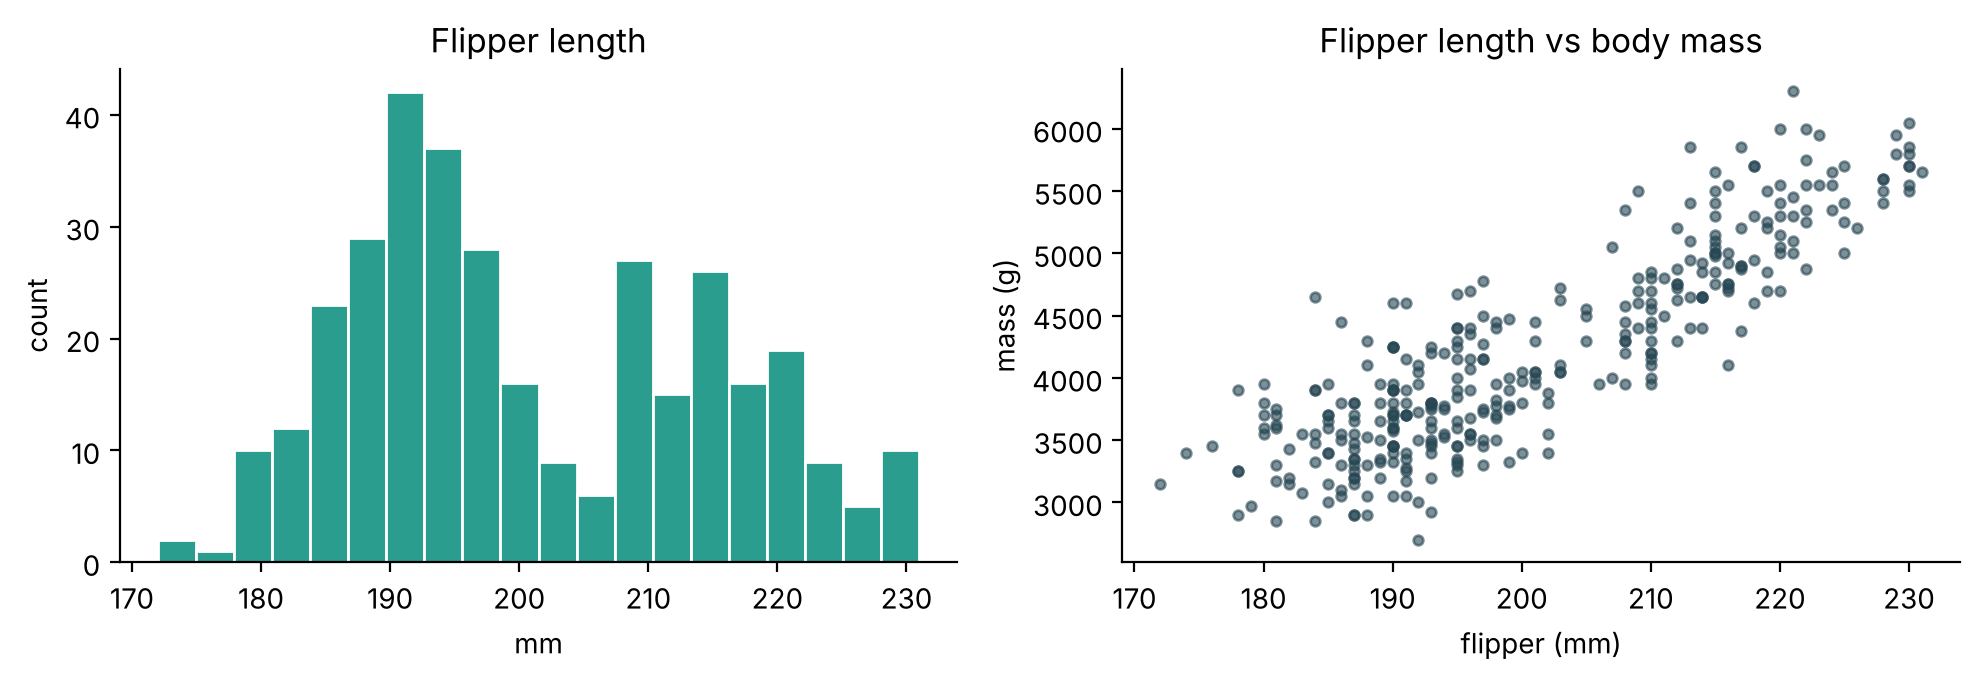

Figure | Axes | axes shape: (2,)


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))   # Figure = the canvas; axes = array of Axes (one per panel)
ax1, ax2 = axes

ax1.hist(df["flipper_length_mm"], bins=20, color="#2a9d8f", edgecolor="white")
ax1.set(title="Flipper length", xlabel="mm", ylabel="count")

ax2.scatter(df["flipper_length_mm"], df["body_mass_g"], s=12, alpha=.6, color="#264653")
ax2.set(title="Flipper length vs body mass", xlabel="flipper (mm)", ylabel="mass (g)")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)   # every Axes method works on that one panel only
fig.tight_layout()
plt.show()
print(type(fig).__name__, "|", type(ax1).__name__, "| axes shape:", axes.shape)

*Two things to notice already. Flipper length is **bimodal**: two humps, which hints at hidden groups (species). Mass and flipper length are strongly related. Every Axes method has a matching `ax.set_*`, and `ax.set(...)` sets several at once.*

**Intentional error: mismatched lengths** (this happens when you filter `x` but not `y`):

ValueError: x and y must be the same size

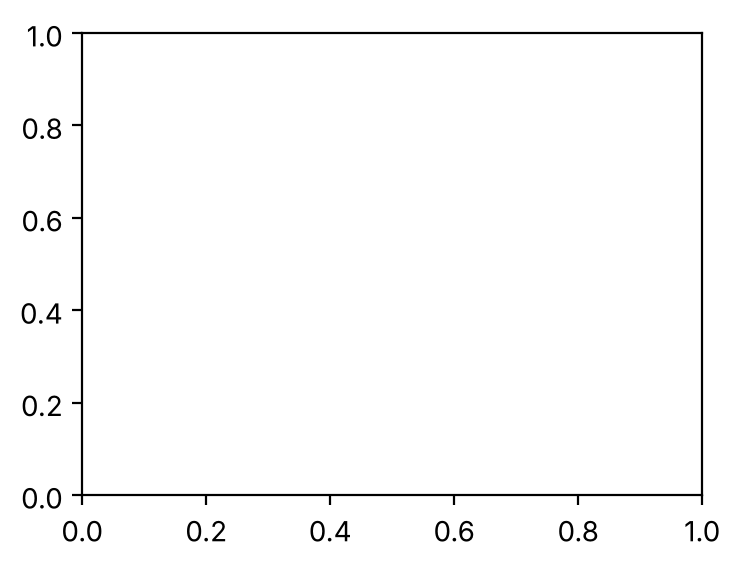

In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
x = df["bill_length_mm"]
y = df.loc[df["species"] == "Gentoo", "bill_depth_mm"]   # filtered: shorter than x!
ax.scatter(x, y)

*`ValueError: x and y must be the same size`. Filter the **DataFrame** first and then take both columns from it, so the rows stay aligned (the same lesson as Lesson 3).*

### 3.2 Histogram bins: Freedman–Diaconis by hand

In [4]:
x = df["flipper_length_mm"].to_numpy()
q75, q25 = np.percentile(x, [75, 25])
h_fd = 2 * (q75 - q25) * len(x) ** (-1 / 3)
n_bins = int(np.ceil((x.max() - x.min()) / h_fd))
print(f"IQR = {q75 - q25:.1f} mm -> bin width {h_fd:.2f} mm -> {n_bins} bins")
print("NumPy agrees:", len(np.histogram_bin_edges(x, bins="fd")) - 1, "bins")

IQR = 23.0 mm -> bin width 6.58 mm -> 9 bins
NumPy agrees: 9 bins


### 3.3 KDE from scratch: one broadcasting line
Grid points `(m, 1)` minus data `(n,)` gives an `(m, n)` matrix of all pairwise differences: Lesson 1's broadcasting doing real work.

In [5]:
def gaussian_kde_scratch(data, grid, h):
    """f_h(x) = 1/(n h) * sum_i K((x - x_i)/h), with a Gaussian kernel K."""
    u = (grid[:, None] - data[None, :]) / h            # (m, n) scaled distances
    K = np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)       # kernel value for every (grid point, sample) pair
    return K.sum(axis=1) / (len(data) * h)             # sum over samples -> (m,)

def silverman(data):
    s = data.std(ddof=1)
    iqr = np.subtract(*np.percentile(data, [75, 25]))
    return 0.9 * min(s, iqr / 1.34) * len(data) ** (-1 / 5)

grid = np.linspace(165, 240, 600)
h_s = silverman(x)
dens = gaussian_kde_scratch(x, grid, h_s)
print(f"Silverman bandwidth: {h_s:.2f} mm")
print(f"integrates to 1? {np.trapezoid(dens, grid):.4f}")

Silverman bandwidth: 3.94 mm
integrates to 1? 0.9997


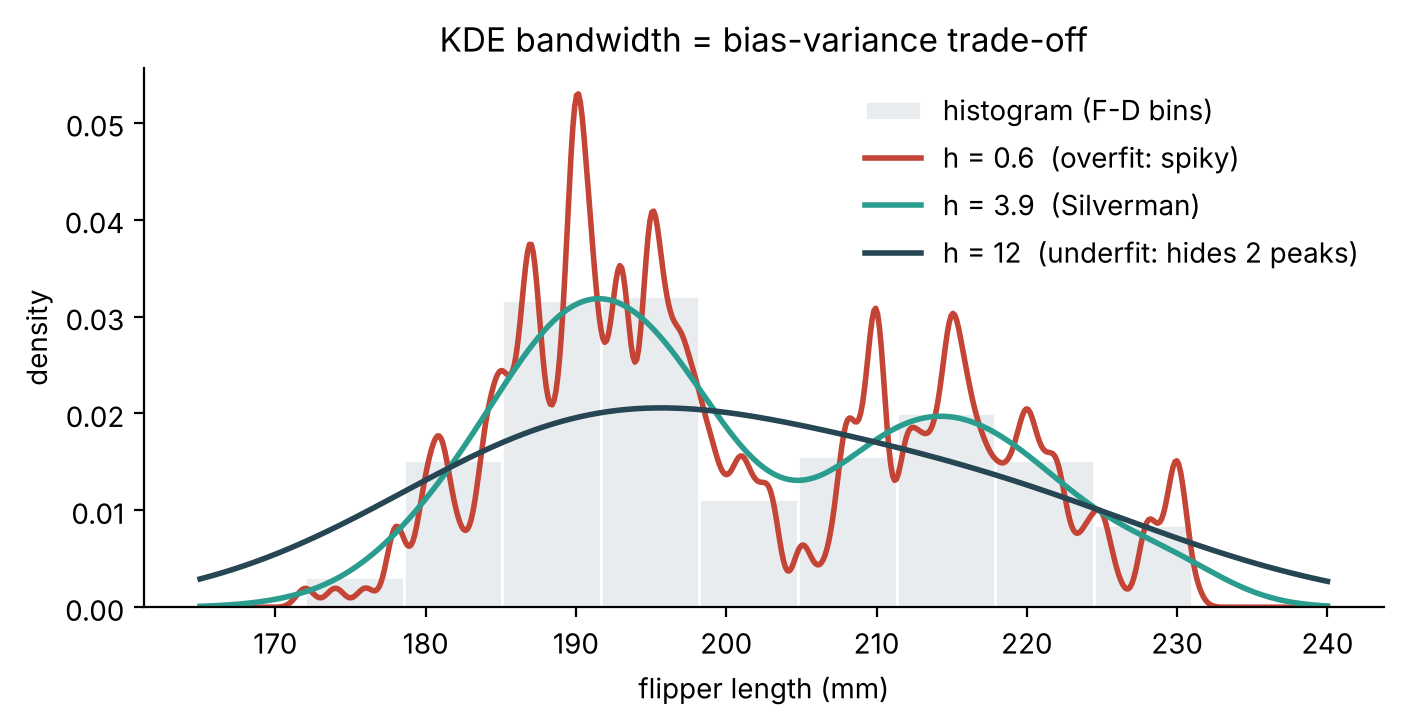

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(x, bins="fd", density=True, color="#e9ecef", edgecolor="white", label="histogram (F-D bins)")
for h, c, lab in [(0.6, "#c44536", "h = 0.6  (overfit: spiky)"),
                  (h_s, "#2a9d8f", f"h = {h_s:.1f}  (Silverman)"),
                  (12, "#264653", "h = 12  (underfit: hides 2 peaks)")]:
    ax.plot(grid, gaussian_kde_scratch(x, grid, h), color=c, lw=2, label=lab)
ax.set(title="KDE bandwidth = bias-variance trade-off", xlabel="flipper length (mm)", ylabel="density")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

*This is the **same dilemma** you'll face in every model: too flexible memorises noise, too rigid misses real structure. Hold onto this picture for Phase 3 (bias–variance) and Phase 4 (k-NN's $k$, tree depth, regularisation strength).*

### 3.4 Correlation matrix from scratch

In [7]:
X = df[num_cols].to_numpy()
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
R = Z.T @ Z / (len(Z) - 1)
print(R.round(3))
print("matches pandas df.corr():", np.allclose(R, df[num_cols].corr().to_numpy()))
print("matches np.corrcoef:     ", np.allclose(R, np.corrcoef(X, rowvar=False)))

[[ 1.    -0.235  0.656  0.595]
 [-0.235  1.    -0.584 -0.472]
 [ 0.656 -0.584  1.     0.871]
 [ 0.595 -0.472  0.871  1.   ]]
matches pandas df.corr(): True
matches np.corrcoef:      True


*Flipper length and body mass correlate at 0.87, so they are partly redundant for a linear model. Now look at bill length vs bill depth: **−0.24**. Penguins with longer bills have shallower bills? Hold that thought.*

---
## 4 · With libraries (the professional way)
### 4.1 `scipy` and seaborn KDEs agree with yours

scipy matches scratch: True


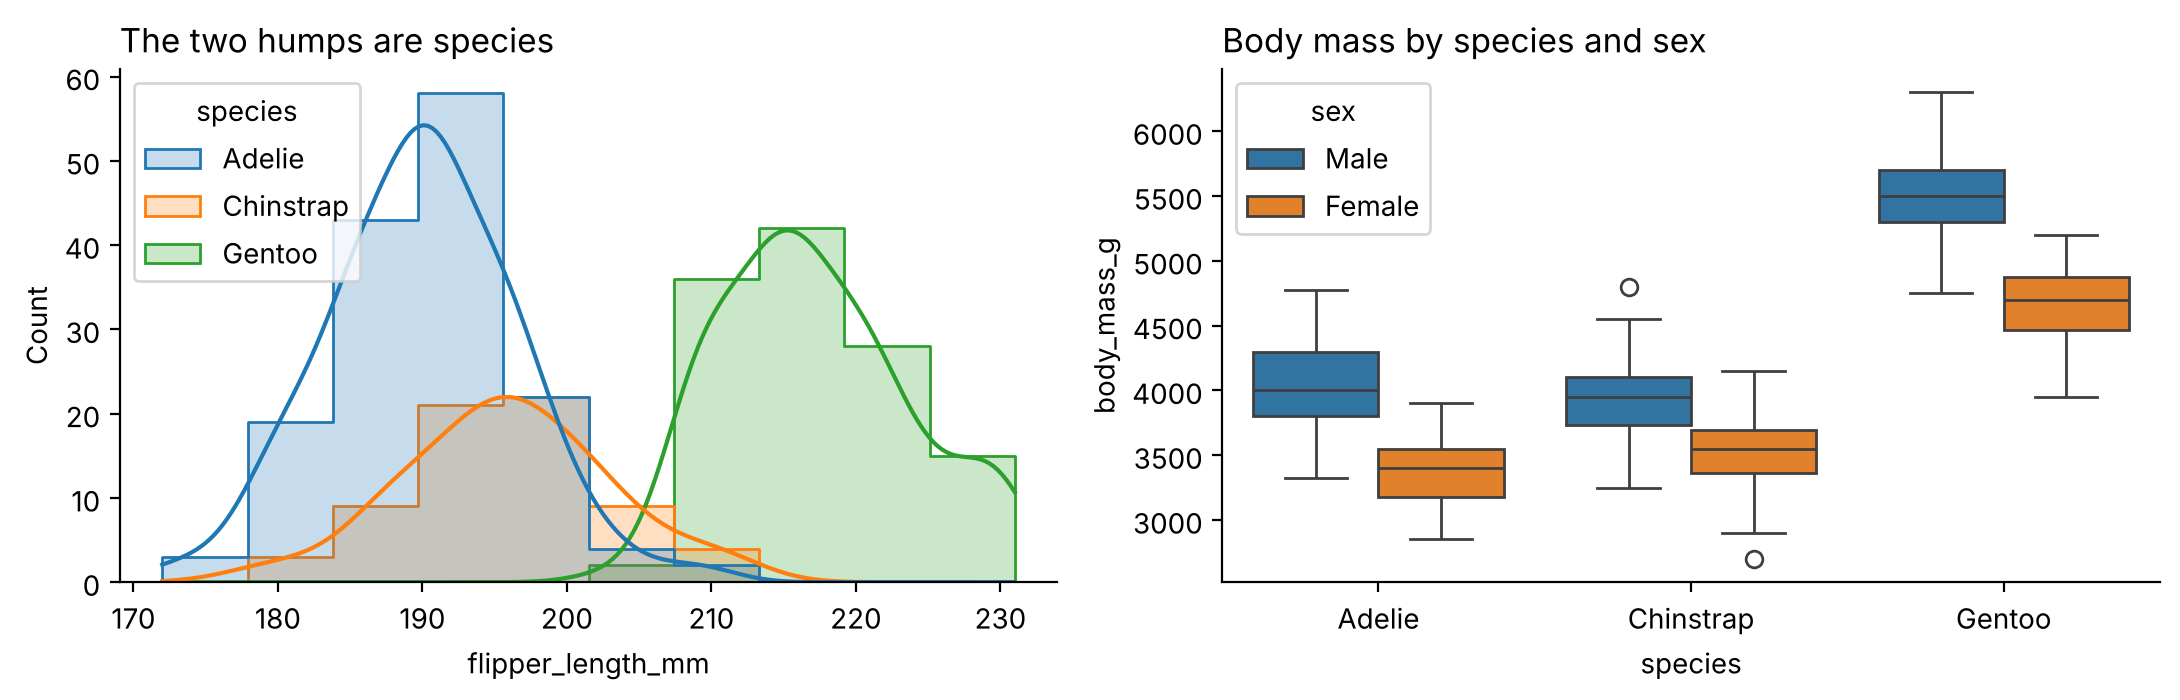

In [8]:
from scipy.stats import gaussian_kde
kde_sp = gaussian_kde(x, bw_method=h_s / x.std(ddof=1))     # scipy's bandwidth = factor x sample std
print("scipy matches scratch:", np.allclose(kde_sp(grid), dens))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df, x="flipper_length_mm", hue="species", kde=True, element="step", ax=axes[0])
axes[0].set_title("The two humps are species", loc="left")
sns.boxplot(df, x="species", y="body_mass_g", hue="sex", ax=axes[1])
axes[1].set_title("Body mass by species and sex", loc="left")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

*Seaborn takes a DataFrame plus column names, and `hue=` splits by group automatically. That is a `groupby` drawn as a chart. Every seaborn function accepts `ax=`, so it slots straight into your Matplotlib layouts. The bimodal flipper distribution resolves into species, and Gentoo are clearly separable.*

### 4.2 Target balance and the relationship overview

species counts: {'Adelie': 151, 'Gentoo': 123, 'Chinstrap': 68}


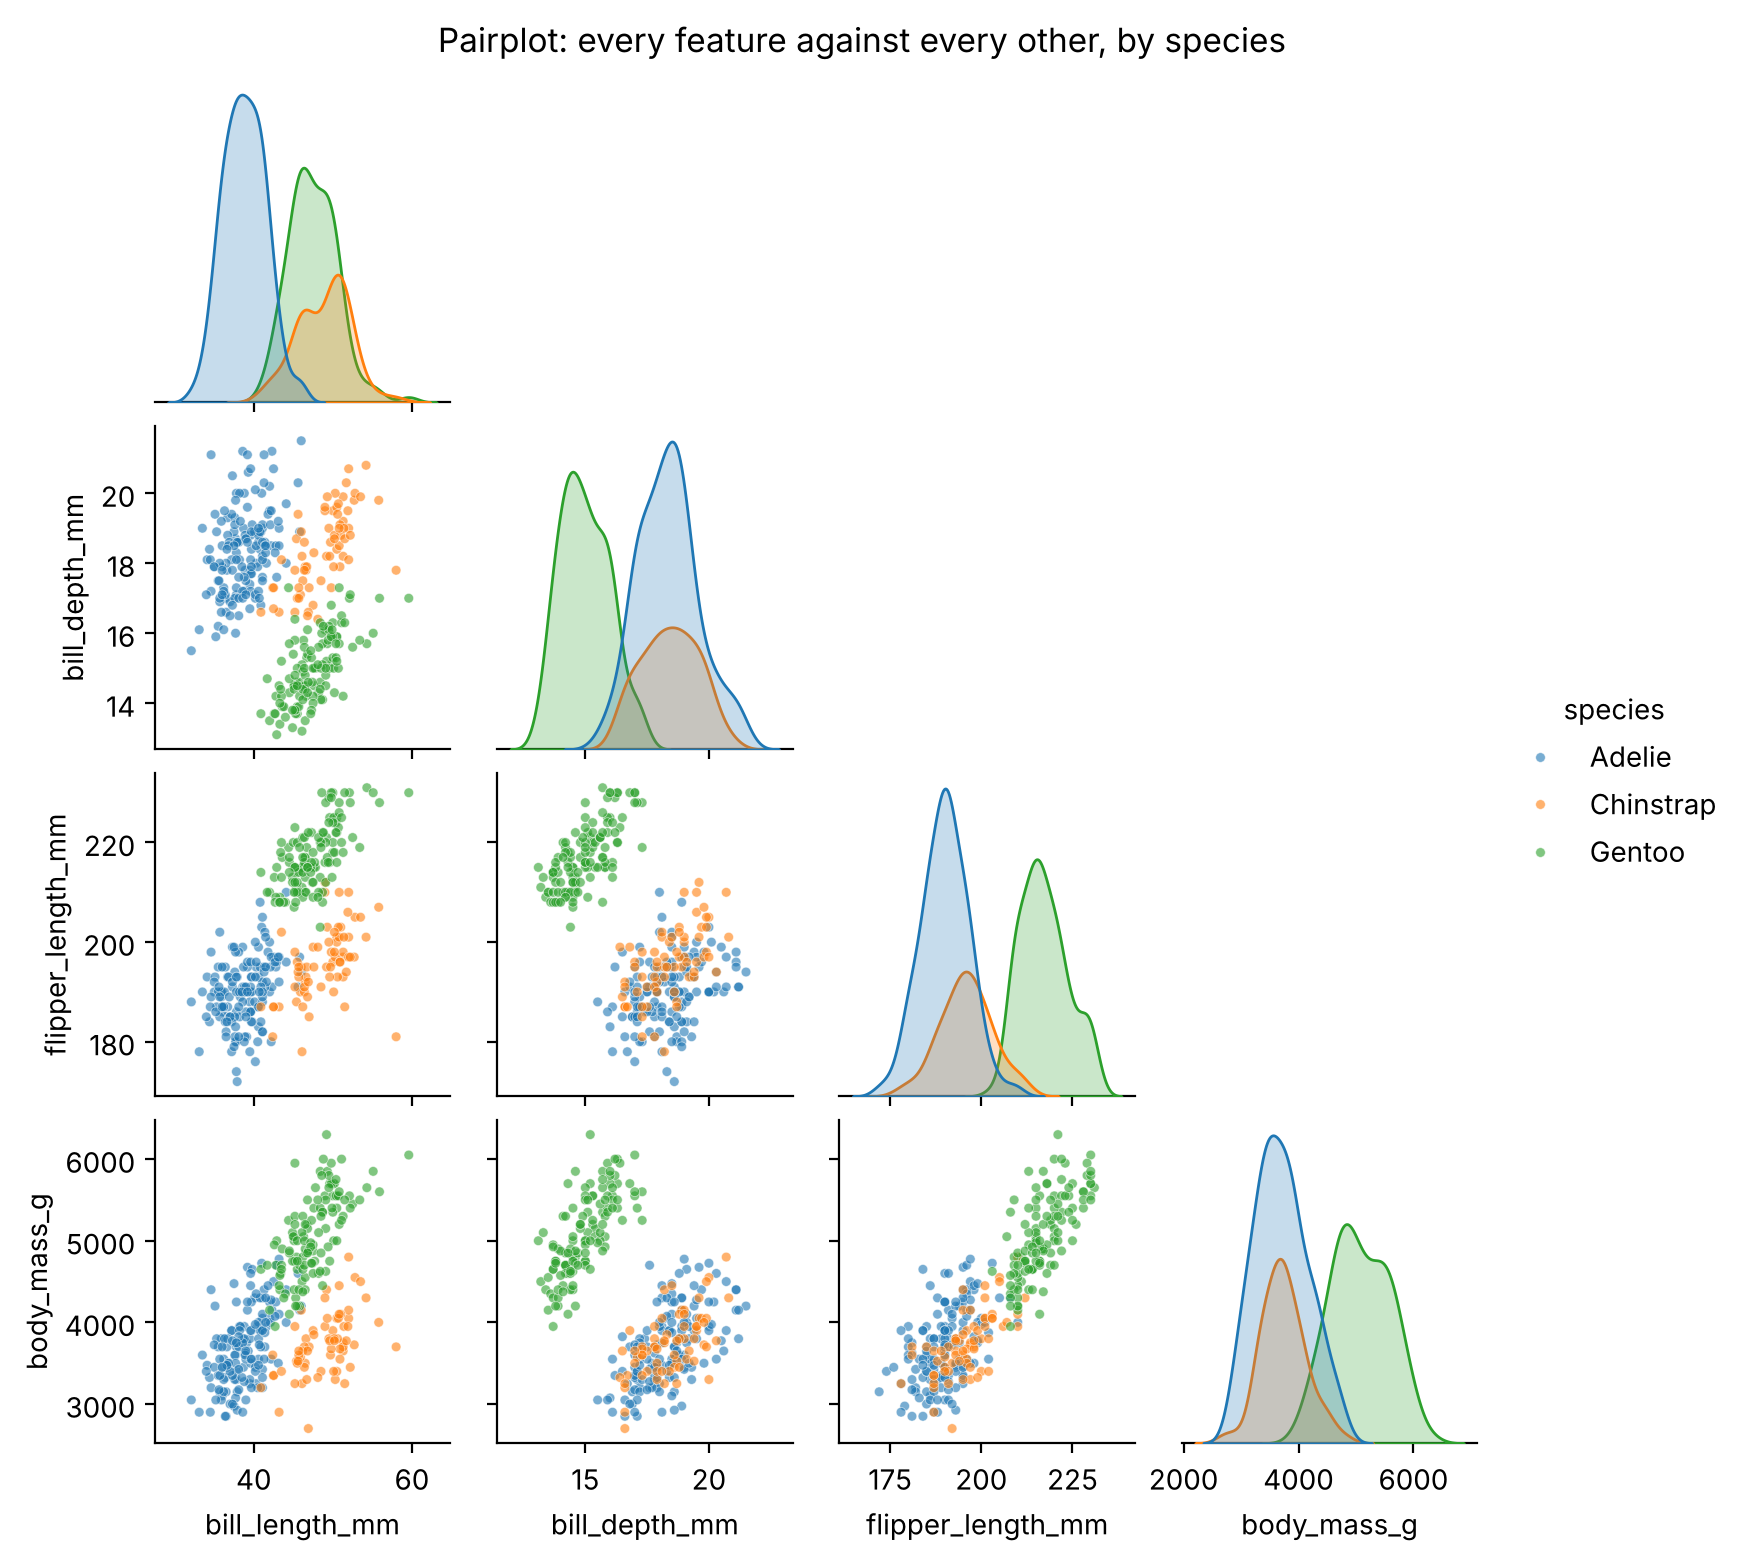

In [9]:
print("species counts:", df["species"].value_counts().to_dict())
g = sns.pairplot(df, vars=num_cols, hue="species", corner=True, plot_kws=dict(s=12, alpha=.6), height=1.9)
g.figure.suptitle("Pairplot: every feature against every other, by species", y=1.02)
plt.show()

*Classes are moderately imbalanced (Chinstrap is the smallest). The pairplot is the fastest single EDA chart there is: distributions on the diagonal, relationships below it. Look at the bill_length × bill_depth panel: **within each colour the trend goes up**.*

### 4.3 Simpson's paradox: the chart a correlation table can't give you

In [10]:
r_all = df["bill_length_mm"].corr(df["bill_depth_mm"])
r_by = df.groupby("species").apply(lambda t: t["bill_length_mm"].corr(t["bill_depth_mm"]), include_groups=False)
print(f"overall r = {r_all:.3f}")
print("within-species r:", r_by.round(3).to_dict())

overall r = -0.235
within-species r: {'Adelie': 0.391, 'Chinstrap': 0.654, 'Gentoo': 0.643}


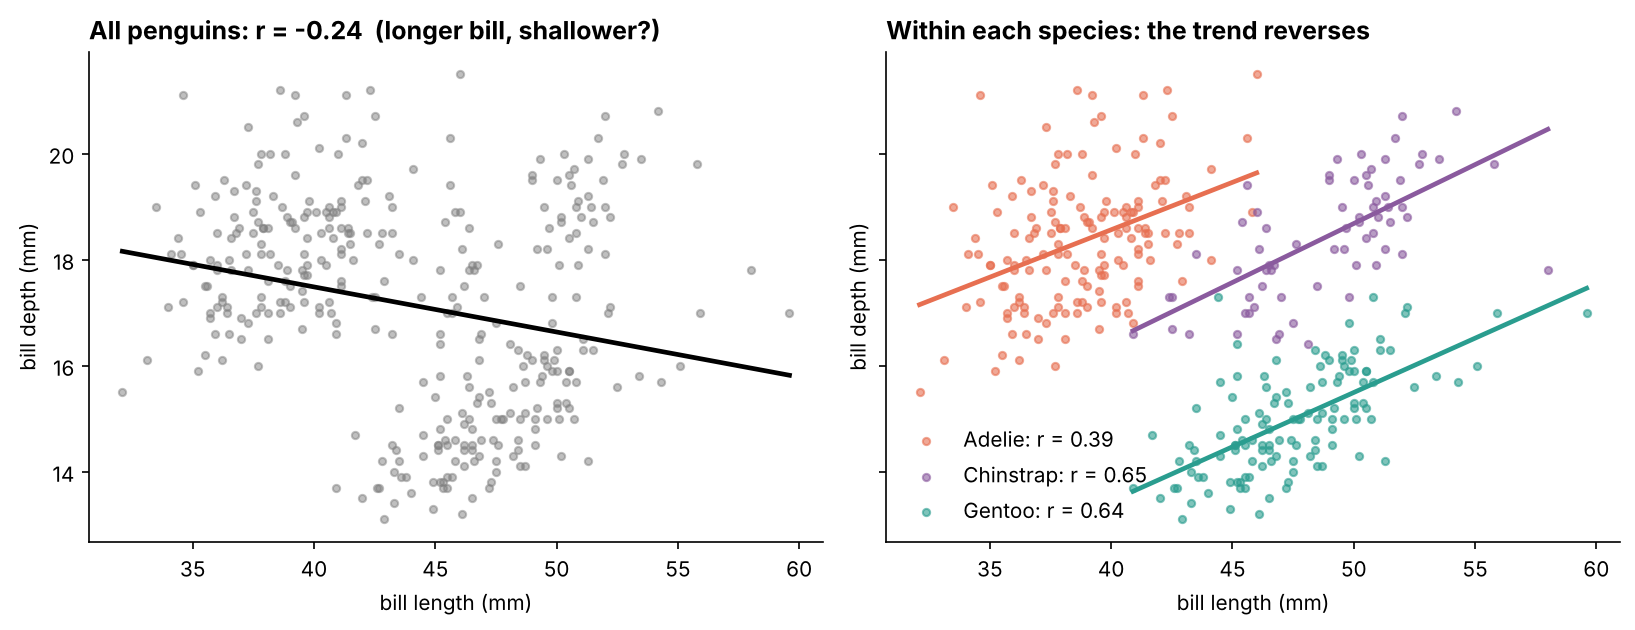

In [11]:
palette = dict(zip(["Adelie", "Chinstrap", "Gentoo"], ["#e76f51", "#8a5a9e", "#2a9d8f"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), dpi=150, sharex=True, sharey=True)
sns.regplot(df, x="bill_length_mm", y="bill_depth_mm", ax=axes[0], ci=None,
            scatter_kws=dict(s=12, alpha=.5, color="grey"), line_kws=dict(color="black"))
axes[0].set_title(f"All penguins: r = {r_all:.2f}  (longer bill, shallower?)", loc="left", fontweight="bold")
for sp, col in palette.items():
    sns.regplot(df[df.species == sp], x="bill_length_mm", y="bill_depth_mm", ax=axes[1], ci=None,
                scatter_kws=dict(s=12, alpha=.6, color=col), line_kws=dict(color=col), label=f"{sp}: r = {r_by[sp]:.2f}")
axes[1].set_title("Within each species: the trend reverses", loc="left", fontweight="bold")
axes[1].legend(frameon=False, loc="lower left")
for ax in axes:
    ax.set(xlabel="bill length (mm)", ylabel="bill depth (mm)"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("assets/simpsons_paradox.png", bbox_inches="tight"); plt.show()

*Overall the correlation is **negative**, but within every species it's **positive** (0.39 to 0.65). The between-species term in the law of total covariance dominates: Gentoo have long but shallow bills, and Adelie short but deep ones. **ML consequence:** a linear model on bill length alone, without species, learns the wrong sign. Group-aware EDA is how you catch this before a stakeholder does.*

| From scratch | Library |
|---|---|
| `fig, axes = plt.subplots(...)` + `ax.hist/scatter` | `sns.histplot / scatterplot(..., ax=ax)` |
| Freedman–Diaconis by hand | `bins="fd"` |
| `gaussian_kde_scratch` + Silverman | `scipy.stats.gaussian_kde`, `sns.kdeplot(bw_adjust=...)` |
| `Z.T @ Z / (n-1)` | `df.corr()`, `sns.heatmap(df.corr(), annot=True)` |
| per-group `corr` | `sns.lmplot(..., hue=...)`, `pairplot(hue=...)` |

---
## 🎬 Demo visuals for your post
### Demo A: bandwidth GIF, from overfit to underfit (`assets/kde_bandwidth.gif`)

In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter
hs = np.geomspace(0.4, 20, 60)
hs = np.r_[hs, hs[::-1]]                                   # sweep there and back for a seamless loop
fig, ax = plt.subplots(figsize=(7, 4), dpi=100)
def update(k):
    h = hs[k]; ax.clear()
    ax.hist(x, bins="fd", density=True, color="#e9ecef", edgecolor="white")
    ax.plot(grid, gaussian_kde_scratch(x, grid, h), color="#2a9d8f", lw=2.5)
    ax.plot(x, np.full_like(x, -0.001), "|", color="#264653", alpha=.4)
    state = "OVERFIT: chasing noise" if h < 1.5 else ("UNDERFIT: peaks merged" if h > 8 else "about right")
    ax.set_title(f"bandwidth h = {h:5.2f} mm  ->  {state}", loc="left", fontweight="bold")
    ax.set_ylim(-0.003, 0.06); ax.set_xlabel("flipper length (mm)"); ax.set_ylabel("density")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
anim = FuncAnimation(fig, update, frames=len(hs))
anim.save("assets/kde_bandwidth.gif", writer=PillowWriter(fps=15))
plt.close(fig)
print("Saved assets/kde_bandwidth.gif")

Saved assets/kde_bandwidth.gif


### Demo B: interactive bandwidth slider (`assets/kde_slider.html`)

In [13]:
import plotly.graph_objects as go
h_vals = np.round(np.geomspace(0.4, 20, 30), 2)
figp = go.Figure()
figp.add_trace(go.Histogram(x=x, histnorm="probability density", nbinsx=n_bins, marker_color="#e9ecef", name="histogram"))
for i, h in enumerate(h_vals):
    figp.add_trace(go.Scatter(x=grid, y=gaussian_kde_scratch(x, grid, h), mode="lines",
                              line=dict(color="#2a9d8f", width=3), visible=(i == 12), name=f"KDE h={h}"))
steps = [dict(method="update", label=str(h),
              args=[{"visible": [True] + [j == i for j in range(len(h_vals))]},
                    {"title": f"Bandwidth h = {h} mm"}]) for i, h in enumerate(h_vals)]
figp.update_layout(title=f"Bandwidth h = {h_vals[12]} mm", template="simple_white", showlegend=False,
                   xaxis_title="flipper length (mm)", yaxis_title="density", height=450,
                   sliders=[dict(active=12, steps=steps, currentvalue=dict(prefix="h: "))])
figp.write_html("assets/kde_slider.html", include_plotlyjs="cdn")
print("Saved assets/kde_slider.html")

Saved assets/kde_slider.html


### Demo C: the Simpson's paradox chart is already saved (`assets/simpsons_paradox.png`). It's your strongest post image this week.

---
## 6 · Exercises (answers hidden; send your code when ready)
Work in `lesson04_exercises.ipynb`.

1. **(Easy) Object model:** Build a 2×2 grid of the four numeric penguin features as histograms with `plt.subplots(2, 2)`. Loop over `axes.flat`, give each its own title and x-label, and set one overall title with `fig.suptitle`.
2. **(Easy) Missing values & balance:** Make one figure with two panels: (a) % missing per column, (b) count per species *split by island*. What does panel (b) tell you about using `island` as a feature?
3. **(Medium) Correlation heatmap:** Plot your from-scratch `R` with `sns.heatmap` (annotated, diverging colormap centred at 0, masked upper triangle). Then plot it again **per species**. Which pairs change the most, and why?
4. **(Medium–Hard) Choose h by cross-validation:** For the flipper data, compute the **leave-one-out log-likelihood** $\sum_i \log \hat f_{h,-i}(x_i)$ (the KDE built without point $i$, evaluated at $x_i$) for a grid of $h$ values. Vectorise it with an $(n\times n)$ distance matrix and zero the diagonal. Plot it against $h$. How does the best $h$ compare with Silverman's? *(This is your first cross-validation, which is Phase 3's core tool.)*
5. **(Challenge) Prove the paradox numerically:** Using the law of total covariance from section 2, compute the within-group and between-group covariance terms for bill length/depth. Show that they sum to the overall covariance (use `ddof=0` throughout so the identity is exact). Which term is negative?

## 7 · Mini-quiz
1. You see `plt.title("A")` set the title on the wrong panel of a 2-panel figure. Why, and what's the fix?
2. What happens to a KDE as $h \to 0$ and as $h \to \infty$? Map each to overfitting or underfitting.
3. A feature has correlation 0.02 with the target. Can you safely drop it? Give one reason why not.
4. Why does `pairplot(hue="species")` reveal something `df.corr()` hides?

## 8 · Common mistakes & interview questions
**Common mistakes**
- **Only looking at summary statistics.** Plot the distributions too (Anscombe's quartet).
- **Mixing pyplot state calls and `ax` calls**, which puts titles and labels on the wrong panels.
- **Default bins and bandwidth accepted blindly.** Try a few, because they change the story.
- **Ignoring groups.** Aggregate trends can reverse (Simpson's paradox).
- **Reading correlation as causation**, or treating "low Pearson r" as "no relationship" (it misses non-linear patterns).
- **EDA on the full dataset, then choosing features from it.** Strictly, feature decisions should be made on training data only, to avoid optimistic bias.
- **Charts without units, titles or readable axes.** If a stakeholder can't read it, it doesn't count.

**Interview questions**
1. Walk me through your EDA process on a new tabular dataset.
2. What is Simpson's paradox? Give an example, and say how you'd guard against it.
3. Explain the bias–variance trade-off using a histogram or KDE.
4. How would you detect multicollinearity visually and numerically?
5. Pearson vs Spearman correlation: when do you use each?
6. How would you check that production data still looks like the training data?

---
### ✅ Lesson 4 checklist
- [ ] Notebook runs top to bottom
- [ ] Exercises 1–5 attempted
- [ ] Quiz answered
- [ ] Post: Simpson's paradox chart or bandwidth GIF + write-up (see `SOCIAL_PACK.md`)
- [ ] `git commit -m "Lesson 4: EDA visualisation, KDE from scratch, Simpson's paradox"` + `git push`

**Next lesson:** Git & GitHub workflow in Git Bash: branches, meaningful commits, pull requests and project READMEs, applied to *this* repo.